# 보팅 앙상블

단일 모델을 앙상블하여 더 나은 예측을 하는 앙상블 모델을 만들어 보도록 하자.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import set_config
set_config(display="text")

from sklearn import datasets

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier

from sklearn.model_selection import GridSearchCV

# 데이터 분리 
from sklearn.model_selection import train_test_split

# 정확도 계산
from sklearn.metrics import accuracy_score

# 손글씨 데이터 로드

In [2]:
# 선생님과 동일한 결과를 위해 랜덤시드 설정 
np.random.seed(5)

# 숫자의 손글씨 데이터 로드 
mnist = datasets.load_digits()

# 입력 데이터와 정답을 저장 
features, labels = mnist.data, mnist.target

# 8:2로 데이터를 분류 -> 학습 데이터와 테스트 데이터, 학습 데이터 정답과 테스트 데이터 정답을 생성한다!!!
X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2)

# 단일 모델 정확도 측정

의사결정트리, knn, svm 모델의 정확도를 측정

In [3]:
# 의사 결정 트리에 지티계수로 처리 하도록 설정 더 빠른 피드백을 받을 수 잇음 
dtree = DecisionTreeClassifier(
    criterion='gini', 
    max_depth=8, 
    max_features=32, 
    random_state=100
  ).fit(X_train, y_train)

# 테스트 데이터로 예측!! 
dtree_predicted = dtree.predict(X_test)
dtree_predicted


array([5, 2, 5, 5, 5, 3, 2, 2, 3, 1, 9, 2, 8, 2, 1, 1, 5, 7, 0, 4, 5, 9,
       8, 2, 1, 3, 4, 7, 5, 2, 8, 1, 2, 9, 8, 1, 4, 3, 4, 9, 5, 5, 6, 0,
       1, 7, 2, 9, 8, 7, 2, 9, 1, 1, 0, 6, 7, 7, 2, 1, 6, 1, 3, 6, 1, 3,
       2, 2, 8, 1, 4, 7, 2, 6, 0, 3, 5, 1, 2, 8, 3, 6, 4, 0, 4, 7, 5, 7,
       8, 5, 7, 8, 5, 1, 8, 7, 5, 9, 4, 9, 9, 0, 8, 8, 7, 4, 8, 3, 2, 8,
       5, 2, 7, 4, 4, 8, 9, 7, 4, 7, 0, 5, 9, 8, 2, 3, 2, 4, 4, 8, 0, 5,
       2, 9, 7, 1, 5, 5, 9, 1, 8, 8, 9, 4, 3, 8, 7, 5, 9, 9, 9, 5, 1, 0,
       8, 7, 2, 3, 4, 1, 0, 0, 3, 6, 4, 7, 7, 0, 5, 9, 2, 8, 7, 9, 7, 5,
       0, 3, 3, 8, 5, 7, 5, 6, 8, 4, 1, 5, 1, 1, 6, 9, 9, 7, 8, 6, 4, 6,
       8, 8, 6, 4, 3, 8, 0, 5, 7, 8, 2, 7, 3, 2, 2, 9, 3, 6, 9, 6, 0, 1,
       0, 2, 9, 0, 3, 2, 5, 5, 8, 9, 2, 5, 0, 8, 3, 7, 4, 3, 7, 9, 2, 6,
       1, 2, 1, 4, 0, 7, 9, 0, 6, 4, 3, 8, 3, 0, 3, 9, 2, 2, 5, 2, 6, 5,
       3, 4, 0, 7, 5, 9, 1, 8, 7, 3, 4, 2, 5, 1, 3, 0, 0, 9, 3, 8, 8, 3,
       8, 8, 6, 6, 2, 6, 7, 5, 2, 1, 5, 7, 5, 4, 5,

In [4]:
# knn 최근접 ( n_neighbors=299 이값을 구하는 방법이 필요함!! )
knn = KNeighborsClassifier(n_neighbors=299).fit(X_train, y_train)

# 예측
knn_predicted = knn.predict(X_test)
knn_predicted

array([5, 2, 5, 5, 5, 3, 2, 2, 3, 5, 9, 8, 7, 7, 1, 1, 5, 7, 0, 4, 5, 9,
       0, 2, 1, 3, 4, 7, 5, 2, 1, 1, 2, 9, 8, 1, 4, 0, 7, 9, 5, 5, 6, 0,
       1, 7, 2, 9, 4, 7, 3, 9, 5, 2, 8, 6, 7, 7, 8, 1, 6, 1, 3, 6, 3, 3,
       2, 6, 8, 1, 4, 7, 1, 6, 0, 0, 5, 1, 8, 5, 2, 6, 4, 0, 4, 7, 5, 7,
       8, 9, 7, 9, 5, 1, 1, 7, 5, 9, 7, 9, 3, 0, 7, 8, 7, 4, 8, 3, 8, 8,
       5, 2, 7, 4, 4, 8, 9, 7, 4, 0, 0, 9, 9, 8, 2, 3, 8, 4, 4, 8, 0, 5,
       2, 9, 4, 9, 6, 9, 9, 7, 8, 0, 9, 4, 3, 8, 7, 5, 5, 9, 3, 3, 1, 0,
       8, 7, 2, 8, 4, 1, 0, 0, 3, 6, 4, 7, 7, 0, 4, 9, 2, 8, 7, 9, 7, 2,
       0, 3, 3, 8, 9, 7, 0, 6, 8, 4, 8, 5, 1, 1, 6, 9, 9, 7, 9, 6, 4, 6,
       0, 1, 6, 9, 3, 5, 0, 2, 7, 8, 2, 7, 3, 8, 3, 9, 3, 0, 9, 6, 0, 4,
       0, 8, 5, 0, 4, 3, 9, 2, 8, 9, 2, 5, 0, 8, 3, 7, 4, 3, 7, 9, 2, 6,
       1, 2, 1, 7, 0, 7, 9, 0, 6, 4, 9, 8, 3, 0, 8, 9, 2, 2, 5, 2, 6, 6,
       3, 4, 0, 7, 6, 5, 3, 8, 7, 3, 4, 2, 5, 1, 3, 0, 0, 9, 3, 8, 8, 3,
       5, 8, 6, 6, 2, 6, 7, 3, 3, 1, 5, 7, 5, 4, 5,

In [11]:
# c, gamma 최적의 값을 from sklearn.model_selection import GridSearchCV 이걸 활용해 찾을수 있다 우선 찾았다 치고 입력 
# 학습!!
# probability=True 내부에서 확률 값을 담으면서 계산 그래야 확률값을 읽어 올수 있음!! predict_proba() 사용하려면 필요!! 
svm = SVC(C=0.1, gamma=0.003, random_state=100, probability=True).fit(X_train, y_train)

# 예측 검증!! 
svm_predicted = svm.predict(X_test)
svm_predicted

c:\workspaces\git_root\AI_Learning\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


array([5, 2, 5, 5, 5, 3, 2, 2, 3, 9, 9, 8, 7, 9, 1, 1, 5, 7, 0, 4, 5, 9,
       0, 2, 1, 3, 4, 7, 5, 2, 1, 1, 2, 9, 8, 1, 4, 9, 7, 9, 5, 5, 6, 0,
       1, 7, 2, 9, 9, 7, 3, 9, 9, 1, 9, 6, 7, 7, 8, 1, 6, 1, 3, 6, 1, 3,
       2, 6, 8, 1, 4, 7, 1, 6, 0, 9, 5, 1, 9, 9, 1, 6, 4, 0, 4, 7, 9, 7,
       8, 9, 7, 8, 5, 1, 1, 7, 5, 9, 7, 9, 9, 0, 7, 8, 7, 4, 8, 3, 2, 8,
       5, 2, 7, 4, 4, 8, 9, 7, 4, 5, 0, 5, 9, 8, 2, 3, 2, 4, 4, 8, 0, 5,
       2, 9, 4, 9, 6, 5, 9, 9, 9, 0, 9, 4, 3, 8, 7, 5, 9, 9, 9, 5, 1, 0,
       8, 7, 2, 8, 4, 1, 0, 0, 3, 6, 4, 7, 7, 0, 4, 9, 2, 9, 7, 9, 9, 2,
       0, 3, 3, 9, 5, 7, 5, 6, 8, 4, 1, 5, 1, 1, 6, 9, 9, 9, 9, 6, 4, 6,
       0, 1, 6, 5, 3, 9, 0, 2, 7, 8, 9, 7, 3, 8, 3, 9, 3, 9, 9, 6, 0, 4,
       0, 9, 9, 0, 4, 3, 5, 9, 8, 9, 2, 5, 0, 9, 3, 7, 4, 3, 7, 9, 2, 6,
       1, 2, 1, 7, 0, 9, 5, 0, 6, 4, 1, 8, 3, 0, 9, 9, 2, 2, 5, 2, 6, 6,
       9, 4, 0, 7, 1, 5, 9, 8, 9, 3, 4, 2, 5, 1, 3, 0, 0, 9, 3, 8, 9, 3,
       9, 8, 6, 6, 2, 6, 7, 5, 3, 1, 5, 7, 5, 4, 5,

In [6]:
# 개별 모델별 정확도 출력!!
print("[accuarcy]")
print("dtree:",accuracy_score(y_test, dtree_predicted))
print("knn:",accuracy_score(y_test, knn_predicted))
print("svm:",accuracy_score(y_test, svm_predicted))

[accuarcy]
dtree: 0.8111111111111111
knn: 0.8944444444444445
svm: 0.8916666666666667


### 소프트 보팅 또는 하드 보팅은 sklearn의 voting classifier를 사용하여 쉽게 구현할 수 있다.

In [16]:
svm_proba = svm.predict_proba(X_test)

# 각각 이미지가 0~9 일 확률 
print(svm_proba[0:2])

[[9.22515531e-04 1.01327420e-03 2.25718789e-03 1.01392313e-03
  1.36243315e-03 9.59941622e-01 6.63231528e-04 2.83342185e-03
  2.61712052e-02 3.82118508e-03]
 [1.63128401e-03 2.37955756e-03 9.36939979e-01 2.46152811e-03
  1.88206091e-03 6.52957706e-03 1.39711689e-03 4.02203760e-03
  3.53994634e-02 7.35739593e-03]]


In [20]:
dtree_proba = dtree.predict_proba(X_test)

# 각각 이미지가 0~9 일 확률 
print(dtree_proba[0:3])

[[0.         0.         0.         0.         0.         1.
  0.         0.         0.         0.        ]
 [0.         0.         1.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.0952381  0.66666667
  0.         0.04761905 0.19047619 0.        ]]


# 하드 보팅  

하드 보팅은 일반적인 투표와 같이, 각각의 분류기의 예측값들을 모아, 가장 많은 득표를 받은 예측값으로 최종 결론을 내는 방식.

In [31]:
# 3가지 모델을 기반으로 하드 보팅을 통해 최적의 예측 모델 생성!!
voting_clf =  VotingClassifier(estimators=[
                    ('knn', knn),
                    ('svm', svm), 
                    ('decision_tree', dtree)
                  ], 
                  weights=[1,1,1],              # 가중치설정 
                  voting='hard'                 # hard / soft ( 하드 보팅 또는 소프트 보팅 설정 )
                ).fit(X_train, y_train)

hard_voting_predicted = voting_clf.predict(X_test)

c:\workspaces\git_root\AI_Learning\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [32]:
# 단독 개별 모델모다 앙상블을 통해 보팅한 모델이 확률이 높아진 예 
print("[accuarcy]")
print("dtree:",accuracy_score(y_test, dtree_predicted))
print("knn:",accuracy_score(y_test, knn_predicted))
print("svm:",accuracy_score(y_test, svm_predicted))
print("hard voting:",accuracy_score(y_test, hard_voting_predicted))

[accuarcy]
dtree: 0.8111111111111111
knn: 0.8944444444444445
svm: 0.8916666666666667
hard voting: 0.9194444444444444


# 소프트 보팅

소프트 보팅은 각각의 분류 모델의 predict_proba()을 활용하여, 모든 분류값들의 확률들을 더해서, 가장 높은 점수를 획득한 분류값으로 최종 결론을 내는 방식.

In [34]:
voting_soft_clf =  VotingClassifier(estimators=[
                    ('knn', knn),
                    ('svm', svm), 
                    ('decision_tree', dtree)
                  ], 
                  weights=[1,1,1],              # 가중치설정 
                  voting='soft'                 # hard / soft ( 하드 보팅 또는 소프트 보팅 설정 )
                ).fit(X_train, y_train)

soft_voting_predicted = voting_soft_clf.predict(X_test)

c:\workspaces\git_root\AI_Learning\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [35]:
# 단독 개별 모델모다 앙상블을 통해 보팅한 모델이 확률이 높아진 예 
print("[accuarcy]")
print("dtree:",accuracy_score(y_test, dtree_predicted))
print("knn:",accuracy_score(y_test, knn_predicted))
print("svm:",accuracy_score(y_test, svm_predicted))
print("hard voting:",accuracy_score(y_test, hard_voting_predicted))
print("soft voting:",accuracy_score(y_test, soft_voting_predicted))

[accuarcy]
dtree: 0.8111111111111111
knn: 0.8944444444444445
svm: 0.8916666666666667
hard voting: 0.9194444444444444
soft voting: 0.9


# 정확도 비교 시각화

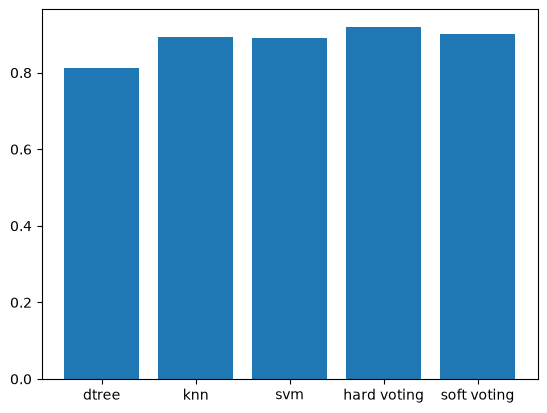

In [45]:
x = np.arange(5)

plt.bar(
  x,  
  height=[
    accuracy_score(y_test, dtree_predicted),
    accuracy_score(y_test, knn_predicted),
    accuracy_score(y_test, svm_predicted),
    accuracy_score(y_test, hard_voting_predicted),
    accuracy_score(y_test, soft_voting_predicted)
  ]
)

# x 축에 항목별 이름 설정 
plt.xticks(x, ['dtree', 'knn', 'svm', 'hard voting', 'soft voting'])

plt.show()
